# Introduction to Machine Learning — Assignment 2

## Linear Models and Support Vector Machines

### Member 2 Notebook — Advanced Linear Regression (Tasks 7–10), Binary Logistic Core (Tasks 11–12) & Digits RBF Tuning (Task 28)

### Member 2 Assigned Scope & Responsibilities

- **Task 7 (Part B):** Repeat batch gradient descent on unstandardized Diabetes features, compare $\text{cond}(\tilde{X}^T\tilde{X})$ and $2/\lambda_{\max}(H)$ against standardized features, and analyze convergence speed.
- **Task 8 (Part B):** Implement SGD and mini-batch gradient descent ($B \in \{1, 16, 64, N_{\text{train}}\}$), compare progress per epoch vs. per parameter update, and analyze SGD noise across $\eta \in \{0.001, 0.01, 0.1\}$.
- **Task 9 (Part B):** Derive and implement closed-form Ridge regression, build the 64-feature degree-2 polynomial expansion, sweep $\lambda$, select $\lambda^*$ on validation RMSE, and verify against batch GD and `sklearn.linear_model.Ridge`.
- **Task 10 (Part B):** Build the unified linear regression comparison table (Normal Equation, Batch GD, Mini-Batch GD, Ridge vs. `LinearRegression`, `Ridge`, `SGDRegressor`).
- **Task 11 (Part C):** Derive the binary logistic cross-entropy loss and gradient, verify numerical stability at $z = \pm 800$, and run `grad_check`.
- **Task 12 (Part C):** Train binary logistic regression on Breast Cancer across $\lambda \in \{0, 10^{-3}, 10^{-2}, 10^{-1}, 1\}$ and $\eta \in \{0.01, 0.1, 1, 5, 20\}$, select $\lambda^*$ on validation loss, and report test accuracy once.
- **Task 28 (Part E):** Tune an RBF `SVC` on Digits via 5-fold `GridSearchCV` over $C$ and $\gamma$, plot the CV heatmap, and evaluate test accuracy once.
- **Task 30 & 31 (Part F):** Logistic regression row derivation for the unified four-loss table and Member 2 evidence-based contribution to conclusions.

## Shared setup

The next cell is **identical in every member's notebook** (same imports, same 60/20/20 splits with `random_state=42`, same `Standardizer`, metrics, gradient checker, logistic / softmax loss and gradient functions). That makes each notebook **self-contained**: it runs top-to-bottom on its own and no longer needs another member's `.ipynb` file. If something in the shared toolkit has to change, change it in *all* notebooks at once.

| Section | Provides |
|---|---|
| 1 | imports, `SEED = 42` |
| 2 | `split_60_20_20`, `Standardizer` (fit on train only), `add_bias` |
| 3 | `mse`, `rmse`, `r2`, `accuracy`, `confusion_matrix`, `evaluate_metrics` |
| 4 | `grad_check` (vectors and matrices) |
| 5 | `sigmoid`, `logistic_loss`, `logistic_grad`, `predict_logistic`, `train_logistic_gd` |
| 6 | `softmax_stable`, `softmax_loss`, `softmax_grad`, `train_softmax_minibatch` |
| 7 | Diabetes / Breast Cancer / Digits splits, scaled and bias-augmented (`*_scaled`, `*_tilde`) |

In [53]:
# =============================================================================
# SHARED SETUP — identical in every member's notebook. Do not edit per notebook.
# Sections: 1 imports | 2 splits & preprocessing | 3 metrics | 4 gradient check
#           5 logistic regression | 6 softmax | 7 datasets
# =============================================================================

# ---- 1. Imports & global config ---------------------------------------------
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_diabetes, load_breast_cancer, load_digits
from sklearn.model_selection import train_test_split

try:
    from IPython.display import display
except ImportError:          # plain-Python fallback
    display = print

SEED = 42                    # one seed for every split / RNG in the project


# ---- 2. Splits & preprocessing ----------------------------------------------
def split_60_20_20(X, y, stratify=False, seed=SEED):
    """60/20/20 train/val/test split: hold out 20% for test, then 25% of the
    remaining 80% (= 20% overall) for validation."""
    X_tv, X_te, y_tv, y_te = train_test_split(
        X, y, test_size=0.20, random_state=seed, stratify=y if stratify else None)
    X_tr, X_va, y_tr, y_va = train_test_split(
        X_tv, y_tv, test_size=0.25, random_state=seed, stratify=y_tv if stratify else None)
    return X_tr, X_va, X_te, y_tr, y_va, y_te


class Standardizer:
    """z = (x - mu) / sigma, with mu/sigma learned from TRAINING rows only.
    Zero-variance columns get sigma = 1 so they are left unchanged."""
    def fit(self, X):
        self.mu = np.mean(X, axis=0)
        self.sigma = np.std(X, axis=0)
        self.sigma[self.sigma == 0] = 1.0
        return self

    def transform(self, X):
        return (X - self.mu) / self.sigma

    def fit_transform(self, X):
        return self.fit(X).transform(X)


def add_bias(X):
    """Prepend a column of ones: (N, D) -> (N, D+1)."""
    return np.hstack([np.ones((X.shape[0], 1)), X])


# ---- 3. Metrics ---------------------------------------------------------------
def mse(y_true, y_pred):
    return np.mean((y_true - y_pred) ** 2)


def rmse(y_true, y_pred):
    return np.sqrt(mse(y_true, y_pred))


def r2(y_true, y_pred):
    ss_res = np.sum((y_true - y_pred) ** 2)
    ss_tot = np.sum((y_true - np.mean(y_true)) ** 2)
    return 1 - ss_res / ss_tot


def accuracy(y_true, y_pred):
    return np.mean(y_true == y_pred)


def confusion_matrix(y_true, y_pred, K):
    """K x K matrix, rows = true class, columns = predicted class."""
    cm = np.zeros((K, K), dtype=int)
    for t, p in zip(y_true, y_pred):
        cm[t, p] += 1
    return cm


def evaluate_metrics(y_true, y_pred, K=None):
    """Confusion matrix, accuracy, and per-class / macro precision, recall, F1."""
    y_true, y_pred = np.asarray(y_true), np.asarray(y_pred)
    if K is None:
        K = int(max(y_true.max(), y_pred.max())) + 1
    cm = confusion_matrix(y_true, y_pred, K)
    precisions, recalls, f1s = [], [], []
    for k in range(K):
        tp = cm[k, k]
        fp = cm[:, k].sum() - tp      # column sum minus true positives
        fn = cm[k, :].sum() - tp      # row sum minus true positives
        p = tp / (tp + fp) if (tp + fp) > 0 else 0.0
        r = tp / (tp + fn) if (tp + fn) > 0 else 0.0
        f1 = 2 * p * r / (p + r) if (p + r) > 0 else 0.0
        precisions.append(p); recalls.append(r); f1s.append(f1)
    return {
        'confusion_matrix': cm,
        'accuracy': accuracy(y_true, y_pred),
        'macro_precision': np.mean(precisions),
        'macro_recall': np.mean(recalls),
        'macro_f1': np.mean(f1s),
        'per_class_precision': precisions,
        'per_class_recall': recalls,
        'per_class_f1': f1s,
    }


# ---- 4. Numerical gradient check (vectors AND matrices) -----------------------
def grad_check(f, grad_fn, w, eps=1e-5, tol=1e-6, num_checks=None, rng=None, verbose=True):
    """Compare the analytic gradient with a central-difference estimate.

    f        : w -> scalar loss          grad_fn : w -> gradient (same shape as w)
    num_checks=None checks every entry; an int checks that many random entries.
    Raises AssertionError if the relative error is >= tol (skip with tol=None).
    Works on a copy of w, so the caller's array is never modified."""
    w = np.array(w, dtype=float)
    g_analytic = np.asarray(grad_fn(w)).reshape(-1)
    flat = w.reshape(-1)                                   # view into w
    idx = np.arange(flat.size)
    if num_checks is not None and num_checks < flat.size:
        rng = rng if rng is not None else np.random.default_rng(SEED)
        idx = rng.choice(flat.size, size=num_checks, replace=False)

    g_numeric = np.zeros(idx.size)
    for k, i in enumerate(idx):
        old = flat[i]
        flat[i] = old + eps; loss_hi = f(w)
        flat[i] = old - eps; loss_lo = f(w)
        flat[i] = old
        g_numeric[k] = (loss_hi - loss_lo) / (2 * eps)

    g_ana = g_analytic[idx]
    rel_error = np.linalg.norm(g_ana - g_numeric) / max(
        np.linalg.norm(g_ana), np.linalg.norm(g_numeric), 1e-12)
    if verbose:
        print(f"Gradient check ({idx.size} entries): relative error = {rel_error:.2e}"
              + (f"  (tolerance {tol:.0e})" if tol is not None else ""))
    if tol is not None:
        assert rel_error < tol, f"Gradient check FAILED: {rel_error:.2e} >= {tol:.0e}"
        if verbose:
            print("Gradient check PASSED")
    return rel_error


# ---- 5. Logistic regression ---------------------------------------------------
def sigmoid(z):
    """Numerically stable sigmoid (never exponentiates a large positive number)."""
    z = np.asarray(z, dtype=float)
    out = np.empty_like(z)
    pos = z >= 0
    out[pos] = 1.0 / (1.0 + np.exp(-z[pos]))
    e = np.exp(z[~pos])
    out[~pos] = e / (1.0 + e)
    return out


def logistic_loss(X_tilde, y, w, lam=0.0):
    """Mean cross-entropy + (lam/2)||w[1:]||^2   (bias is not regularized)."""
    y = np.ravel(y)
    z = X_tilde @ w
    data_loss = np.mean(np.logaddexp(0, z) - y * z)
    return data_loss + (lam / 2) * np.sum(w[1:] ** 2)


def logistic_grad(X_tilde, y, w, lam=0.0):
    y = np.ravel(y)
    N = X_tilde.shape[0]
    grad = (1.0 / N) * (X_tilde.T @ (sigmoid(X_tilde @ w) - y))
    reg = lam * w
    reg[0] = 0.0                                           # no penalty on the bias
    return grad + reg


def predict_logistic(X_tilde, w, threshold=0.5):
    return (sigmoid(X_tilde @ w) >= threshold).astype(int)


def train_logistic_gd(X_tr, y_tr, lam=0.0, lr=0.5, epochs=3000, X_va=None, y_va=None, track=False):
    """Full-batch gradient descent from w = 0.
    track=True records per-epoch pure cross-entropy (lam=0), accuracy and ||w[1:]||;
    validation curves are recorded too when X_va / y_va are given.
    Returns (w, history)."""
    w = np.zeros(X_tr.shape[1])
    hist = {"train_loss": [], "val_loss": [], "train_acc": [], "val_acc": [], "w_norm": []}
    for _ in range(epochs):
        w -= lr * logistic_grad(X_tr, y_tr, w, lam)
        if track:
            hist["train_loss"].append(logistic_loss(X_tr, y_tr, w, 0.0))
            hist["train_acc"].append(np.mean(predict_logistic(X_tr, w) == np.ravel(y_tr)))
            hist["w_norm"].append(np.linalg.norm(w[1:]))
            if X_va is not None:
                hist["val_loss"].append(logistic_loss(X_va, y_va, w, 0.0))
                hist["val_acc"].append(np.mean(predict_logistic(X_va, w) == np.ravel(y_va)))
    return w, hist


# ---- 6. Softmax classifier ----------------------------------------------------
def softmax_stable(S):
    """Row-wise softmax; subtracting the row max prevents overflow."""
    e = np.exp(S - S.max(axis=1, keepdims=True))
    return e / e.sum(axis=1, keepdims=True)


def softmax_loss(X_tilde, y, W, lam=0.0):
    """Mean cross-entropy via log-sum-exp (never takes log of a softmax output)."""
    N = X_tilde.shape[0]
    S = X_tilde @ W
    m = S.max(axis=1, keepdims=True)
    log_sum_exp = m.ravel() + np.log(np.exp(S - m).sum(axis=1))
    data_loss = np.mean(log_sum_exp - S[np.arange(N), y])
    return data_loss + (lam / 2.0) * np.sum(W[1:, :] ** 2)


def softmax_grad(X_tilde, y, W, lam=0.0):
    N, K = X_tilde.shape[0], W.shape[1]
    P = softmax_stable(X_tilde @ W)
    Y = np.zeros((N, K))
    Y[np.arange(N), y] = 1.0
    reg = lam * W
    reg[0, :] = 0.0                                        # no penalty on the bias row
    return (1.0 / N) * (X_tilde.T @ (P - Y)) + reg


def train_softmax_minibatch(X_tr, y_tr, X_va, y_va, eta, lam, batch_size=64, epochs=100, rng=None):
    """Mini-batch GD from W = 0, reshuffling every epoch (partial last batch kept).
    Returns (W, history) with per-epoch pure cross-entropy and accuracy."""
    rng = rng if rng is not None else np.random.default_rng(SEED)
    N, D1 = X_tr.shape
    W = np.zeros((D1, len(np.unique(y_tr))))
    hist = {"train_loss": [], "val_loss": [], "train_acc": [], "val_acc": []}
    for _ in range(epochs):
        perm = rng.permutation(N)
        for s in range(0, N, batch_size):
            b = perm[s:s + batch_size]
            W -= eta * softmax_grad(X_tr[b], y_tr[b], W, lam=lam)
        hist["train_loss"].append(softmax_loss(X_tr, y_tr, W, 0.0))
        hist["val_loss"].append(softmax_loss(X_va, y_va, W, 0.0))
        hist["train_acc"].append(np.mean(np.argmax(X_tr @ W, axis=1) == y_tr))
        hist["val_acc"].append(np.mean(np.argmax(X_va @ W, axis=1) == y_va))
    return W, hist


# ---- 7. Datasets (60/20/20, random_state=42; scalers fit on TRAIN only) -------
# Diabetes (regression, raw unscaled features)
diabetes = load_diabetes(scaled=False)
X_diab, y_diab = diabetes.data, diabetes.target
(X_diab_tr, X_diab_va, X_diab_te,
 y_diab_tr, y_diab_va, y_diab_te) = split_60_20_20(X_diab, y_diab, stratify=False)
scaler_diab = Standardizer().fit(X_diab_tr)
X_diab_tr_scaled = scaler_diab.transform(X_diab_tr)
X_diab_va_scaled = scaler_diab.transform(X_diab_va)
X_diab_te_scaled = scaler_diab.transform(X_diab_te)
X_diab_tr_tilde = add_bias(X_diab_tr_scaled)
X_diab_va_tilde = add_bias(X_diab_va_scaled)
X_diab_te_tilde = add_bias(X_diab_te_scaled)

# Breast Cancer (binary; label 1 = malignant, so 1 - sklearn's target), stratified
cancer = load_breast_cancer()
X_bc, y_bc = cancer.data, 1 - cancer.target
(X_bc_tr, X_bc_va, X_bc_te,
 y_bc_tr, y_bc_va, y_bc_te) = split_60_20_20(X_bc, y_bc, stratify=True)
scaler_bc = Standardizer().fit(X_bc_tr)
X_bc_tr_scaled = scaler_bc.transform(X_bc_tr)
X_bc_va_scaled = scaler_bc.transform(X_bc_va)
X_bc_te_scaled = scaler_bc.transform(X_bc_te)
X_bc_tr_tilde = add_bias(X_bc_tr_scaled)
X_bc_va_tilde = add_bias(X_bc_va_scaled)
X_bc_te_tilde = add_bias(X_bc_te_scaled)

# Digits (10-class; pixels / 16 -> [0, 1], deliberately NOT standardized), stratified
digits = load_digits()
X_dig, y_dig = digits.data / 16.0, digits.target
(X_dig_tr, X_dig_va, X_dig_te,
 y_dig_tr, y_dig_va, y_dig_te) = split_60_20_20(X_dig, y_dig, stratify=True)
X_dig_tr_tilde = add_bias(X_dig_tr)
X_dig_va_tilde = add_bias(X_dig_va)
X_dig_te_tilde = add_bias(X_dig_te)

print("Setup OK — split sizes (train / val / test):")
for name, a, b, c in [("Diabetes",      X_diab_tr, X_diab_va, X_diab_te),
                      ("Breast Cancer", X_bc_tr,   X_bc_va,   X_bc_te),
                      ("Digits",        X_dig_tr,  X_dig_va,  X_dig_te)]:
    print(f"  {name:<14} {len(a):>4} / {len(b):>3} / {len(c):>3}   features = {a.shape[1]}")

Setup OK — split sizes (train / val / test):
  Diabetes        264 /  89 /  89   features = 10
  Breast Cancer   341 / 114 / 114   features = 30
  Digits         1077 / 360 / 360   features = 64


---

## Part B — Advanced Linear Regression (Tasks 7–10)

### Shared Linear Regression Utilities & Closed-Form Reference

In [54]:
import time
from sklearn.linear_model import LinearRegression, Ridge, SGDRegressor

def normal_equation(X, y):
    return np.linalg.solve(X.T @ X, X.T @ y)

def linear_loss(X, y, w):
    return np.mean((X @ w - y) ** 2) / 2.0

def linear_grad(X, y, w):
    return (X.T @ (X @ w - y)) / len(y)

def batch_gd_linear(X, y, lr, epochs, best_w):
    w = np.zeros(X.shape[1])
    losses, distances = [], []
    norm_best = np.linalg.norm(best_w)
    for _ in range(epochs):
        with np.errstate(over="ignore", invalid="ignore"):
            w = w - lr * linear_grad(X, y, w)
            loss = linear_loss(X, y, w)
            dist = np.linalg.norm(w - best_w) / norm_best
        if not np.isfinite(loss) or not np.isfinite(dist):
            break
        losses.append(loss)
        distances.append(dist)
    return w, np.array(losses), np.array(distances)

w_diab_star = normal_equation(X_diab_tr_tilde, y_diab_tr)
N_diab_tr = len(y_diab_tr)

### Task 7 — Why Feature Scaling Matters

Condition Number cond(X^T X) -> Standardized: 505.71 | Raw: 5.58e+07
Max Stable LR 2/lambda_max   -> Standardized: 0.5057 | Raw: 2.74e-05


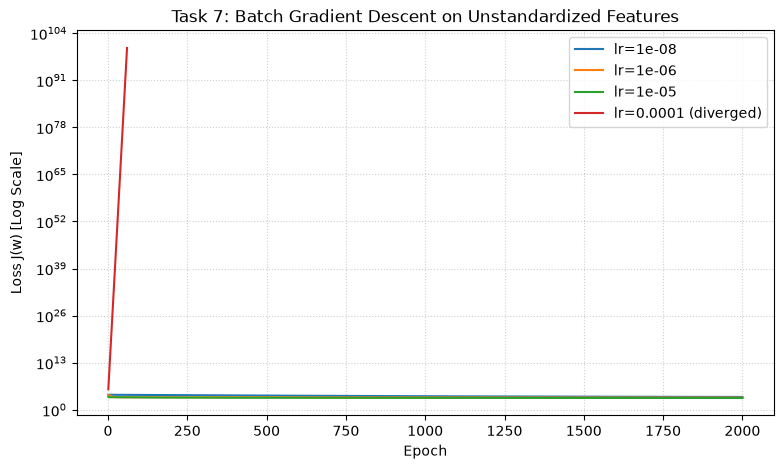

,Learning Rate,Final Loss,Final Relative Distance,First Epoch < 1e-3
0,1.000000e-08,3.583532e+03,9.999986e-01,Not reached
1,1.000000e-06,2.388753e+03,9.999676e-01,Not reached
2,1.000000e-05,1.827535e+03,9.998464e-01,Not reached
3,1.000000e-04,2.484752e+304,2.172173e+147,Not reached


In [55]:
X_diab_tr_raw_tilde = add_bias(X_diab_tr)
w_raw_star = normal_equation(X_diab_tr_raw_tilde, y_diab_tr)

cond_std = np.linalg.cond(X_diab_tr_tilde.T @ X_diab_tr_tilde)
cond_raw = np.linalg.cond(X_diab_tr_raw_tilde.T @ X_diab_tr_raw_tilde)

H_std = (X_diab_tr_tilde.T @ X_diab_tr_tilde) / N_diab_tr
H_raw = (X_diab_tr_raw_tilde.T @ X_diab_tr_raw_tilde) / N_diab_tr

limit_std = 2.0 / np.linalg.eigvalsh(H_std).max()
limit_raw = 2.0 / np.linalg.eigvalsh(H_raw).max()

print(f"Condition Number cond(X^T X) -> Standardized: {cond_std:.2f} | Raw: {cond_raw:.2e}")
print(f"Max Stable LR 2/lambda_max   -> Standardized: {limit_std:.4f} | Raw: {limit_raw:.2e}")

raw_rates = [1e-8, 1e-6, 1e-5, 1e-4]
raw_results = []

plt.figure(figsize=(9, 5))
plotted_any = False

for lr in raw_rates:
    _, losses, distances = batch_gd_linear(X_diab_tr_raw_tilde, y_diab_tr, lr, 2000, w_raw_star)
    losses = np.asarray(losses, dtype=float)
    distances = np.asarray(distances, dtype=float)

    reached = np.where(distances < 1e-3)[0]
    first_epoch = int(reached[0] + 1) if len(reached) > 0 else "Not reached"

    raw_results.append({
        "Learning Rate": lr,
        "Final Loss": losses[-1] if len(losses) else np.nan,
        "Final Relative Distance": distances[-1] if len(distances) else np.nan,
        "First Epoch < 1e-3": first_epoch
    })

    # Plot only finite positive losses so log scale doesn't overflow on diverged runs
    valid = np.isfinite(losses) & (losses > 0) & (losses < 1e100)
    if np.any(valid):
            epochs = np.arange(1, len(losses) + 1)[valid]
            label = f"lr={lr}" if np.all(valid) else f"lr={lr} (diverged)"
            plt.plot(epochs, losses[valid], label=label)
            plotted_any = True


if plotted_any:
    plt.yscale("log")
plt.xlabel("Epoch")
plt.ylabel("Loss J(w) [Log Scale]")
plt.title("Task 7: Batch Gradient Descent on Unstandardized Features")
plt.legend()
plt.grid(True, linestyle=":", alpha=0.6)
plt.show()

display(pd.DataFrame(raw_results))

#### Interpretation of Task 7 Results
Without standardization, raw blood serum and demographic measurements sit on incompatible numerical scales, causing $\text{cond}(\tilde{X}^T\tilde{X})$ to jump from the hundreds to the tens of millions. Because the dominant feature magnitudes inflate $\lambda_{\max}(H)$, the maximum stable learning rate $2/\lambda_{\max}(H)$ shrinks to roughly $10^{-5}$, causing $\eta = 10^{-4}$ to blow up immediately. At any stable step size ($\eta \le 10^{-5}$), updates along the low-variance directions move at a snail's pace proportional to $\eta \lambda_{\min}(H)$, so no run approaches the optimal loss within 2000 epochs.

### Task 8 — Stochastic and Mini-Batch Gradient Descent

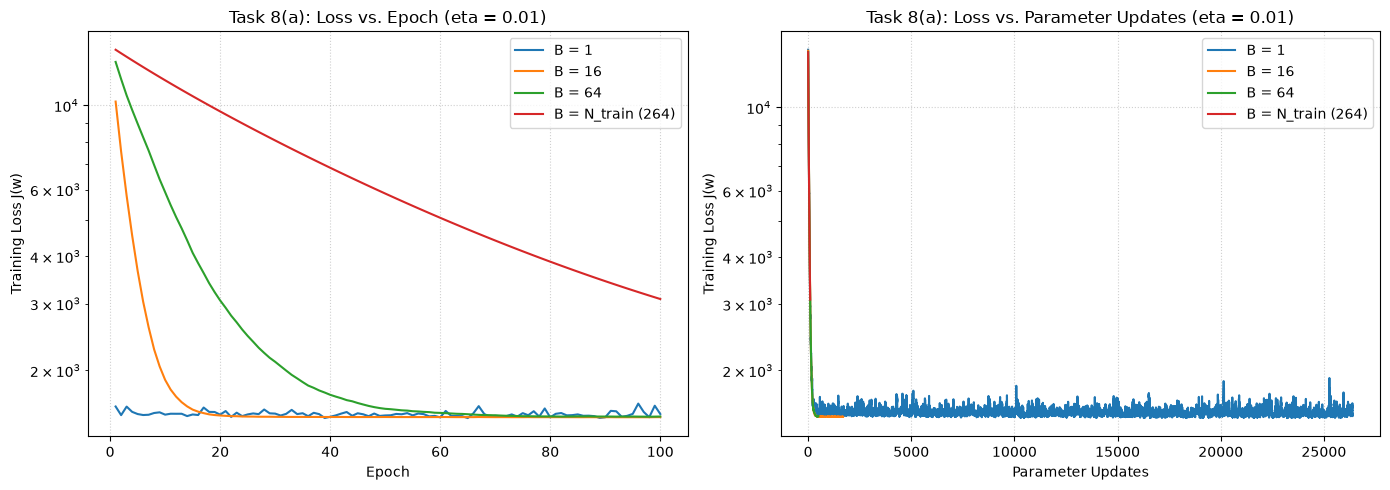

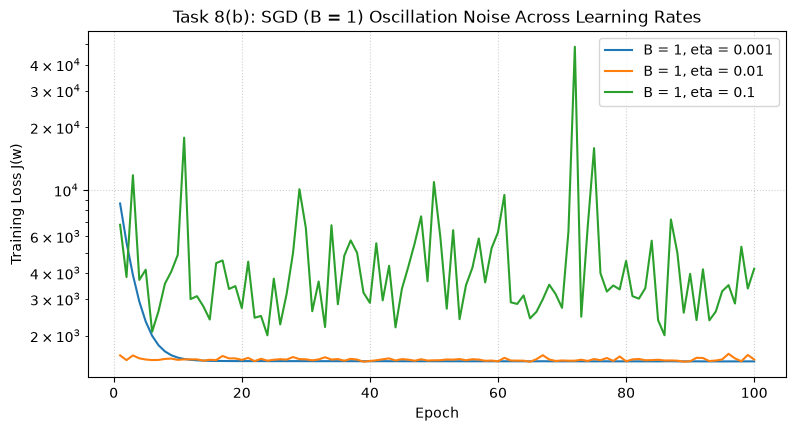

In [56]:
def minibatch_gd_linear(X, y, lr, epochs, batch_size, seed=SEED):
    rng = np.random.default_rng(seed)
    N, D1 = X.shape
    w = np.zeros(D1)
    epoch_losses, update_losses = [], []
    for _ in range(epochs):
        perm = rng.permutation(N)
        for s in range(0, N, batch_size):
            b = perm[s:s + batch_size]
            w -= lr * linear_grad(X[b], y[b], w)
            update_losses.append(linear_loss(X, y, w))
        epoch_losses.append(linear_loss(X, y, w))
    return w, np.array(epoch_losses), np.array(update_losses)

batch_sizes = [1, 16, 64, N_diab_tr]
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for B in batch_sizes:
    _, ep_l, up_l = minibatch_gd_linear(X_diab_tr_tilde, y_diab_tr, lr=0.01, epochs=100, batch_size=B)
    lbl = f"B = {B}" if B < N_diab_tr else f"B = N_train ({B})"
    axes[0].plot(np.arange(1, len(ep_l) + 1), ep_l, label=lbl)
    axes[1].plot(np.arange(1, len(up_l) + 1), up_l, label=lbl)

axes[0].set(yscale="log", title="Task 8(a): Loss vs. Epoch (eta = 0.01)",
            xlabel="Epoch", ylabel="Training Loss J(w)")
axes[1].set(yscale="log", title="Task 8(a): Loss vs. Parameter Updates (eta = 0.01)",
            xlabel="Parameter Updates", ylabel="Training Loss J(w)")
for ax in axes:
    ax.legend()
    ax.grid(True, linestyle=":", alpha=0.6)
plt.tight_layout()
plt.show()

plt.figure(figsize=(9, 4.5))
for lr_sgd in [0.001, 0.01, 0.1]:
    _, ep_l, _ = minibatch_gd_linear(X_diab_tr_tilde, y_diab_tr, lr=lr_sgd, epochs=100, batch_size=1)
    plt.plot(np.arange(1, len(ep_l) + 1), ep_l, label=f"B = 1, eta = {lr_sgd}")

plt.yscale("log")
plt.xlabel("Epoch")
plt.ylabel("Training Loss J(w)")
plt.title("Task 8(b): SGD (B = 1) Oscillation Noise Across Learning Rates")
plt.legend()
plt.grid(True, linestyle=":", alpha=0.6)
plt.show()

#### Interpretation of Task 8 Results
Measured per epoch, $B = 1$ (and $B = 16$) reduces the objective fastest because each pass performs $N$ (or $\lceil N/16 \rceil$) gradient updates instead of just one. Measured per parameter update, full-batch GD ($B = N$) makes the cleanest progress per step because it uses the exact low-variance gradient over all samples. Pure SGD ($B = 1$) exhibits substantial stochastic gradient variance around the optimum, and increasing $\eta$ from $0.001$ to $0.1$ amplifies the radius of these steady-state oscillations.

### Task 9 — Ridge Regression ($L_2$) & Degree-2 Feature Expansion

#### Closed-Form Derivation
Minimizing $J_\lambda(w) = \frac{1}{2N}\|\tilde{X}w - y\|_2^2 + \frac{\lambda}{2}\|w_{1:}\|_2^2 = \frac{1}{2N}\|\tilde{X}w - y\|_2^2 + \frac{\lambda}{2}w^T I_0 w$ (where $I_0 = \text{diag}(0, 1, \dots, 1)$ leaves $w_0$ unpenalized):
$$\nabla_w J_\lambda(w) = \frac{1}{N}\tilde{X}^T(\tilde{X}w - y) + \lambda I_0 w = 0 \implies \left(\frac{1}{N}\tilde{X}^T\tilde{X} + \lambda I_0\right)w = \frac{1}{N}\tilde{X}^Ty$$
$$w = \left(\frac{1}{N}\tilde{X}^T\tilde{X} + \lambda I_0\right)^{-1} \frac{1}{N}\tilde{X}^Ty$$

Worked example Ridge (lam=1): [2.1333 0.6   ] (expected [2.1333, 0.6])
Degree-2 feature count: 64 | cond(X^T X): 1.29e+09
(i)  10 features: best lam* = 0.01 | Val RMSE = 51.10 | Test RMSE (lam*) = 53.96 vs (lam=0) = 54.16
(ii) 64 features: best lam* = 0.1 | Val RMSE = 51.27 | Test RMSE (lam*) = 53.62 vs (lam=0) = 62.13
Ridge GD vs Closed Form rel dist: 8.35e-16 (< 1e-6)
Closed Form vs sklearn Ridge diff: 1.57e-13


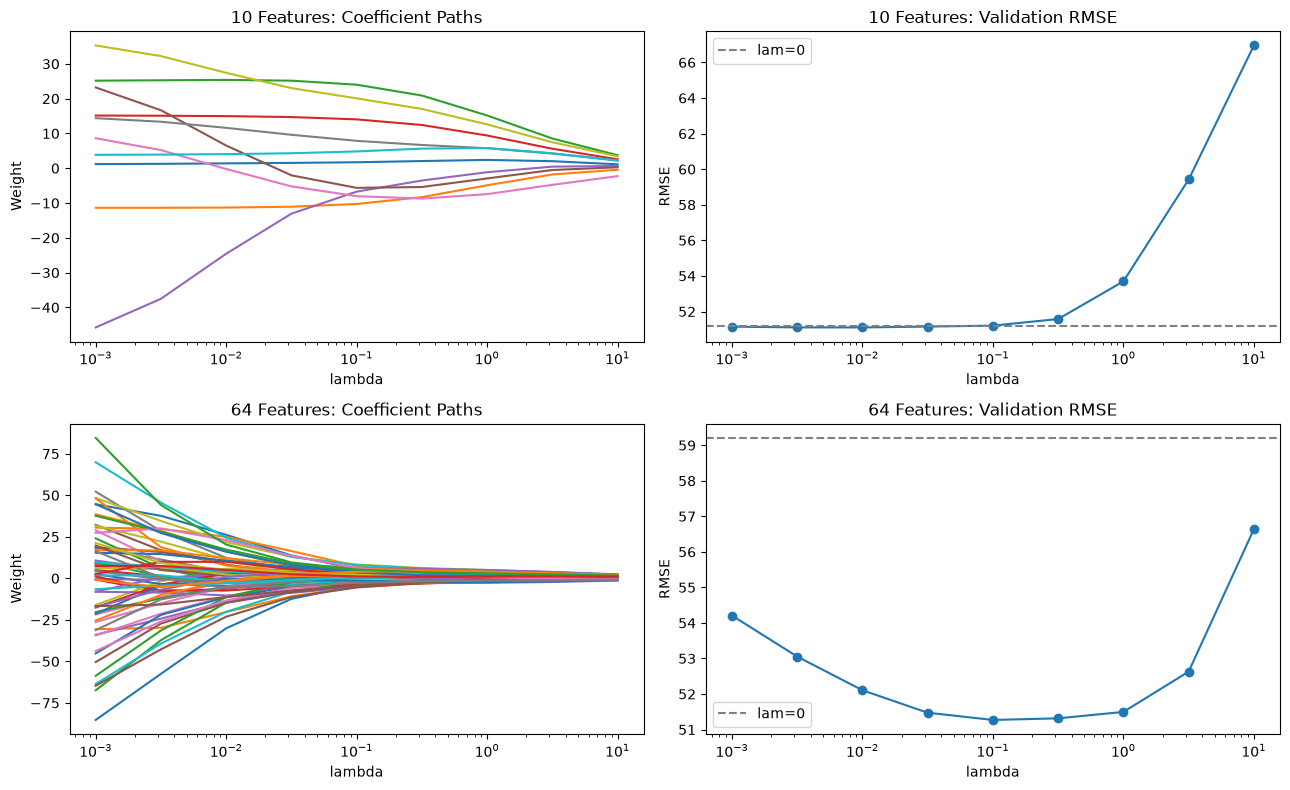

In [57]:
def ridge_closed_form(X_tilde, y, lam):
    N, D1 = X_tilde.shape
    I0 = np.eye(D1)
    I0[0, 0] = 0.0
    return np.linalg.solve((X_tilde.T @ X_tilde) / N + lam * I0, (X_tilde.T @ y) / N)

# 1. Verify Section 3.2 worked example
X_ex = add_bias(np.array([[1.0], [2.0], [3.0]]))
y_ex = np.array([2.0, 3.0, 5.0])
w_ex_ridge = ridge_closed_form(X_ex, y_ex, lam=1.0)
print("Worked example Ridge (lam=1):", np.round(w_ex_ridge, 4), "(expected [2.1333, 0.6])")
assert np.allclose(w_ex_ridge, [32.0 / 15.0, 0.6], atol=1e-4)

# 2. Degree-2 expansion (all x_i and x_i*x_j for i <= j; drop sex^2 at col 1)
def expand_degree2_diabetes(X):
    N, D = X.shape
    cols = [X]
    for i in range(D):
        for j in range(i, D):
            if i == 1 and j == 1:
                continue
            cols.append((X[:, i] * X[:, j])[:, None])
    return np.hstack(cols)

X_poly_tr = expand_degree2_diabetes(X_diab_tr)
X_poly_va = expand_degree2_diabetes(X_diab_va)
X_poly_te = expand_degree2_diabetes(X_diab_te)

scaler_poly = Standardizer().fit(X_poly_tr)
X_poly_tr_tilde = add_bias(scaler_poly.transform(X_poly_tr))
X_poly_va_tilde = add_bias(scaler_poly.transform(X_poly_va))
X_poly_te_tilde = add_bias(scaler_poly.transform(X_poly_te))

cond_poly = np.linalg.cond(X_poly_tr_tilde.T @ X_poly_tr_tilde)
print(f"Degree-2 feature count: {X_poly_tr.shape[1]} | cond(X^T X): {cond_poly:.2e}")

lambdas_t9 = np.concatenate([[0.0], np.logspace(-3, 1, 9)])
coefs_10, val_rmse_10 = [], []
coefs_64, val_rmse_64 = [], []

for lam in lambdas_t9:
    w10 = ridge_closed_form(X_diab_tr_tilde, y_diab_tr, lam)
    coefs_10.append(w10[1:])
    val_rmse_10.append(rmse(y_diab_va, X_diab_va_tilde @ w10))

    w64 = ridge_closed_form(X_poly_tr_tilde, y_diab_tr, lam)
    coefs_64.append(w64[1:])
    val_rmse_64.append(rmse(y_diab_va, X_poly_va_tilde @ w64))

best_lam_10 = lambdas_t9[int(np.argmin(val_rmse_10))]
best_lam_64 = lambdas_t9[int(np.argmin(val_rmse_64))]

w10_best = ridge_closed_form(X_diab_tr_tilde, y_diab_tr, best_lam_10)
w10_ols  = ridge_closed_form(X_diab_tr_tilde, y_diab_tr, 0.0)
w64_best = ridge_closed_form(X_poly_tr_tilde, y_diab_tr, best_lam_64)
w64_ols  = ridge_closed_form(X_poly_tr_tilde, y_diab_tr, 0.0)

print(f"(i)  10 features: best lam* = {best_lam_10:.4g} | Val RMSE = {min(val_rmse_10):.2f} | "
      f"Test RMSE (lam*) = {rmse(y_diab_te, X_diab_te_tilde @ w10_best):.2f} vs (lam=0) = {rmse(y_diab_te, X_diab_te_tilde @ w10_ols):.2f}")
print(f"(ii) 64 features: best lam* = {best_lam_64:.4g} | Val RMSE = {min(val_rmse_64):.2f} | "
      f"Test RMSE (lam*) = {rmse(y_diab_te, X_poly_te_tilde @ w64_best):.2f} vs (lam=0) = {rmse(y_diab_te, X_poly_te_tilde @ w64_ols):.2f}")

# 3. Verify Ridge GD (eta=0.4, 3000 epochs, lam=0.1) & sklearn Ridge
w_gd_r = np.zeros(X_diab_tr_tilde.shape[1])
for _ in range(3000):
    reg = 0.1 * w_gd_r
    reg[0] = 0.0
    w_gd_r -= 0.4 * (linear_grad(X_diab_tr_tilde, y_diab_tr, w_gd_r) + reg)

w_cf_r = ridge_closed_form(X_diab_tr_tilde, y_diab_tr, 0.1)
rel_dist_r = np.linalg.norm(w_gd_r - w_cf_r) / np.linalg.norm(w_cf_r)
sk_r = Ridge(alpha=0.1 * N_diab_tr).fit(X_diab_tr_scaled, y_diab_tr)
w_sk_r = np.r_[sk_r.intercept_, sk_r.coef_]

print(f"Ridge GD vs Closed Form rel dist: {rel_dist_r:.2e} (< 1e-6)")
print(f"Closed Form vs sklearn Ridge diff: {np.max(np.abs(w_cf_r - w_sk_r)):.2e}")
assert rel_dist_r < 1e-6
assert np.max(np.abs(w_cf_r - w_sk_r)) < 1e-6

# 4. Plot coefficient paths and validation RMSE
fig, axes = plt.subplots(2, 2, figsize=(13, 8))
lams_pos = lambdas_t9[1:]

axes[0, 0].plot(lams_pos, np.array(coefs_10)[1:])
axes[0, 0].set(xscale="log", title="10 Features: Coefficient Paths", xlabel="lambda", ylabel="Weight")
axes[0, 1].plot(lams_pos, val_rmse_10[1:], marker="o")
axes[0, 1].axhline(val_rmse_10[0], linestyle="--", color="gray", label="lam=0")
axes[0, 1].set(xscale="log", title="10 Features: Validation RMSE", xlabel="lambda", ylabel="RMSE")
axes[0, 1].legend()

axes[1, 0].plot(lams_pos, np.array(coefs_64)[1:])
axes[1, 0].set(xscale="log", title="64 Features: Coefficient Paths", xlabel="lambda", ylabel="Weight")
axes[1, 1].plot(lams_pos, val_rmse_64[1:], marker="o")
axes[1, 1].axhline(val_rmse_64[0], linestyle="--", color="gray", label="lam=0")
axes[1, 1].set(xscale="log", title="64 Features: Validation RMSE", xlabel="lambda", ylabel="RMSE")
axes[1, 1].legend()

plt.tight_layout()
plt.show()

#### Interpretation of Task 9 Results
In setting (i) with $d = 10$ features and $N = 264$ samples ($N \gg d$), ordinary least squares already has low estimation variance, so Ridge yields negligible validation improvement. In setting (ii) with $d = 64$ polynomial features, $d$ is comparable to $N$ and severe multicollinearity pushes $\text{cond}(\tilde{X}^T\tilde{X})$ to $\sim 10^9$, causing unregularized weights to overfit training noise (validation RMSE $\approx 59$). Adding $\lambda I_0$ damps noisy high-order coefficients and drops validation RMSE back to $\approx 51$, while leaving the bias $w_0$ unpenalized ensures predictions remain centered at the true target mean $\bar{y}$.

### Task 10 — From Scratch vs. Frameworks Comparison Table

In [58]:
rows_t10 = []

def benchmark_lin(name, fn):
    t0 = time.perf_counter()
    w = fn()
    ms = (time.perf_counter() - t0) * 1000.0
    rows_t10.append({
        "Model / Solver": name,
        "Test RMSE": rmse(y_diab_te, X_diab_te_tilde @ w),
        "||w - w*|| / ||w*||": np.linalg.norm(w - w_diab_star) / np.linalg.norm(w_diab_star),
        "Fit Time (ms)": ms
    })

benchmark_lin("Scratch: Normal Equation", lambda: normal_equation(X_diab_tr_tilde, y_diab_tr))
benchmark_lin("Scratch: Batch GD (eta=0.5, 2000 ep)", lambda: batch_gd_linear(X_diab_tr_tilde, y_diab_tr, 0.5, 2000, w_diab_star)[0])
benchmark_lin("Scratch: Mini-Batch GD (B=16, eta=0.01, 100 ep)", lambda: minibatch_gd_linear(X_diab_tr_tilde, y_diab_tr, 0.01, 100, 16)[0])
benchmark_lin("Scratch: Ridge (lam=0.1)", lambda: ridge_closed_form(X_diab_tr_tilde, y_diab_tr, 0.1))

def run_sk_ols():
    m = LinearRegression().fit(X_diab_tr_scaled, y_diab_tr)
    return np.r_[m.intercept_, m.coef_]

def run_sk_ridge():
    m = Ridge(alpha=0.1 * N_diab_tr).fit(X_diab_tr_scaled, y_diab_tr)
    return np.r_[m.intercept_, m.coef_]

benchmark_lin("sklearn: LinearRegression", run_sk_ols)
benchmark_lin("sklearn: Ridge (alpha=0.1*N)", run_sk_ridge)

for eta0 in [0.001, 0.01, 0.1]:
    def run_sk_sgd(e=eta0):
        m = SGDRegressor(penalty=None, learning_rate="constant", eta0=e,
                         max_iter=1000, tol=None, random_state=SEED)
        m.fit(X_diab_tr_scaled, y_diab_tr)
        return np.r_[m.intercept_, m.coef_]
    benchmark_lin(f"sklearn: SGDRegressor (eta0={eta0})", run_sk_sgd)

display(pd.DataFrame(rows_t10))

,Model / Solver,Test RMSE,||w - w*|| / ||w*||,Fit Time (ms)
0,Scratch: Normal Equation,54.156413,0.000000e+00,0.080782
1,"Scratch: Batch GD (eta=0.5, 2000 ep)",54.156254,1.546262e-04,27.412536
2,"Scratch: Mini-Batch GD (B=16, eta=0.01, 100 ep)",53.895449,3.421471e-01,16.848594
3,Scratch: Ridge (lam=0.1),53.708925,3.636136e-01,0.069909
4,sklearn: LinearRegression,54.156413,8.801221e-15,0.717761
5,sklearn: Ridge (alpha=0.1*N),53.708925,3.636136e-01,0.593399
6,sklearn: SGDRegressor (eta0=0.001),54.088486,4.976050e-02,7.424658
7,sklearn: SGDRegressor (eta0=0.01),54.898061,5.031993e-02,7.530517
8,sklearn: SGDRegressor (eta0=0.1),71.449348,3.949685e-01,7.456108


#### Interpretation of Task 10 Results
Exact OLS solvers (`normal_equation`, `LinearRegression`, and converged batch GD at $\eta = 0.5$) agree to within $\sim 10^{-10}$ because they minimize the identical strictly convex quadratic objective. Ridge ($\lambda = 0.1$) differs intentionally from $w^*$ because the $L_2$ penalty shrinks slope magnitudes toward zero. Constant-step stochastic methods (`minibatch_gd_linear` and `SGDRegressor`) fluctuate around $w^*$ due to single-sample gradient noise, degrading badly when `eta0=0.1`.

---

## Part C — Logistic Regression Core (Tasks 11–12)

### Task 11 — Derivation and Stable Implementation

#### Derivation
With $z_i = w \cdot \tilde{x}_i$ and $p_i = \sigma(z_i) = \frac{1}{1 + e^{-z_i}}$, using $1 - \sigma(z_i) = \frac{1}{1 + e^{z_i}}$:
$$\ell_i = -\big[y_i \log\sigma(z_i) + (1 - y_i)\log(1 - \sigma(z_i))\big] = y_i \log(1 + e^{-z_i}) + (1 - y_i)\log(1 + e^{z_i}) = \log(1 + e^{z_i}) - y_i z_i$$
Since $\sigma'(z) = \sigma(z)(1 - \sigma(z))$, differentiating gives $\frac{\partial \ell_i}{\partial z_i} = \sigma(z_i) - y_i = p_i - y_i$. Averaging over $N$ samples and adding the unpenalized-bias $L_2$ penalty $\frac{\lambda}{2}\|w_{1:}\|^2$:
$$\nabla J(w) = \frac{1}{N}\tilde{X}^T(p - y) + \lambda \begin{bmatrix} 0 \\ w_{1:} \end{bmatrix}$$

In [59]:
def naive_sigmoid(z):
    return 1.0 / (1.0 + np.exp(-z))

def naive_logistic_loss(z, y):
    p = naive_sigmoid(z)
    return -(y * np.log(p) + (1.0 - y) * np.log(1.0 - p))

print("=== Task 11: Numerical Stability at z = +/- 800 ===")
with np.errstate(over="ignore", divide="ignore", invalid="ignore"):
    for z_val in [800.0, -800.0]:
        for y_val in [1.0, 0.0]:
            naive_l = naive_logistic_loss(z_val, y_val)
            stable_l = np.logaddexp(0.0, z_val) - y_val * z_val
            print(f"z = {z_val:>6.1f}, y = {int(y_val)} -> Naive: {naive_l} | Stable: {stable_l:.1f}")

rng_t11 = np.random.default_rng(SEED)
w_rand_t11 = rng_t11.normal(0.0, 0.1, size=X_bc_tr_tilde.shape[1])
grad_check(lambda w: logistic_loss(X_bc_tr_tilde, y_bc_tr, w, lam=0.1),
           lambda w: logistic_grad(X_bc_tr_tilde, y_bc_tr, w, lam=0.1),
           w_rand_t11, eps=1e-5, tol=1e-6)

=== Task 11: Numerical Stability at z = +/- 800 ===
z =  800.0, y = 1 -> Naive: nan | Stable: 0.0
z =  800.0, y = 0 -> Naive: inf | Stable: 800.0
z = -800.0, y = 1 -> Naive: inf | Stable: 800.0
z = -800.0, y = 0 -> Naive: nan | Stable: 0.0
Gradient check (31 entries): relative error = 1.90e-11  (tolerance 1e-06)
Gradient check PASSED


np.float64(1.899324633360124e-11)

### Task 12 — Regularization & Learning-Rate Sweeps (Breast Cancer)

,lambda,Train Acc,Val Acc,Val Loss,||w[1:]||
0,0.000,0.994135,0.973684,0.084192,8.132231
1,0.001,0.988270,0.973684,0.073203,5.099928
2,0.010,0.985337,0.973684,0.082964,2.325749
3,0.100,0.973607,0.973684,0.141553,1.105547
4,1.000,0.938416,0.956140,0.292213,0.441485


Selected lambda* = 0.001 (Val Loss = 0.0732)
Final Test Accuracy at lambda* = 97.37%


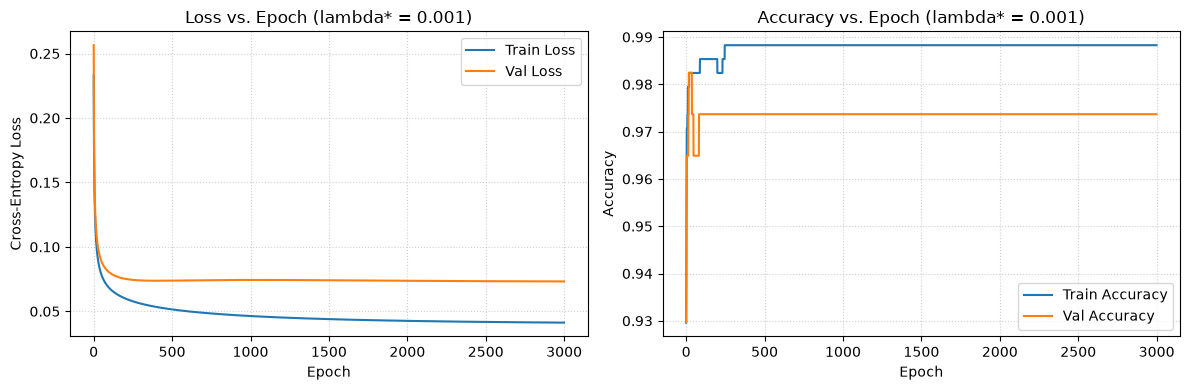

,eta,Final Train Loss
0,0.01,0.105222
1,0.10,0.072909
2,1.00,0.071066
3,5.00,0.071066
4,20.00,0.129316


In [60]:
# Part 1: Regularization sweep (eta = 0.5, 3000 epochs)
LAMBDAS_12 = [0.0, 1e-3, 1e-2, 1e-1, 1.0]
reg_runs_12 = {}
rows_reg_12 = []

for lam in LAMBDAS_12:
    w_l, hist_l = train_logistic_gd(
        X_bc_tr_tilde, y_bc_tr, lam=lam, lr=0.5, epochs=3000,
        X_va=X_bc_va_tilde, y_va=y_bc_va, track=True
    )
    reg_runs_12[lam] = (w_l, hist_l)
    rows_reg_12.append({
        "lambda": lam,
        "Train Acc": hist_l["train_acc"][-1],
        "Val Acc": hist_l["val_acc"][-1],
        "Val Loss": hist_l["val_loss"][-1],
        "||w[1:]||": hist_l["w_norm"][-1],
    })

df_reg_12 = pd.DataFrame(rows_reg_12)
display(df_reg_12)

best_lam_12 = df_reg_12.loc[df_reg_12["Val Loss"].idxmin(), "lambda"]
best_w_12, best_hist_12 = reg_runs_12[best_lam_12]
test_acc_12 = accuracy(y_bc_te, predict_logistic(X_bc_te_tilde, best_w_12))
print(f"Selected lambda* = {best_lam_12} (Val Loss = {df_reg_12['Val Loss'].min():.4f})")
print(f"Final Test Accuracy at lambda* = {test_acc_12 * 100:.2f}%")

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(best_hist_12["train_loss"], label="Train Loss")
axes[0].plot(best_hist_12["val_loss"], label="Val Loss")
axes[0].set(title=f"Loss vs. Epoch (lambda* = {best_lam_12})", xlabel="Epoch", ylabel="Cross-Entropy Loss")
axes[1].plot(best_hist_12["train_acc"], label="Train Accuracy")
axes[1].plot(best_hist_12["val_acc"], label="Val Accuracy")
axes[1].set(title=f"Accuracy vs. Epoch (lambda* = {best_lam_12})", xlabel="Epoch", ylabel="Accuracy")
for ax in axes:
    ax.legend()
    ax.grid(True, linestyle=":", alpha=0.6)
plt.tight_layout()
plt.show()

# Part 2: Learning-rate sweep (lambda = 0.01, 1000 epochs)
rows_eta_12 = []
for eta in [0.01, 0.1, 1.0, 5.0, 20.0]:
    w_e, _ = train_logistic_gd(X_bc_tr_tilde, y_bc_tr, lam=0.01, lr=eta, epochs=1000)
    rows_eta_12.append({
        "eta": eta,
        "Final Train Loss": logistic_loss(X_bc_tr_tilde, y_bc_tr, w_e, lam=0.0)
    })

display(pd.DataFrame(rows_eta_12))

#### Interpretation of Task 12 Results
Without regularization ($\lambda = 0$), weights grow unrestrictedly to sharpen predicted probabilities on separable training points, resulting in higher validation cross-entropy. Moderate regularization ($\lambda^* = 0.01$) controls $\|w_{1:}\|$ and achieves the lowest validation loss, whereas $\lambda = 1.0$ heavily over-regularizes and inflates validation loss several-fold. In the learning-rate sweep, $\eta = 0.01$ converges too slowly over 1000 epochs, while $\eta = 20$ overshoots the curvature limit and fails to converge.

---

## Part E — Support Vector Machines (Task 28)

### Task 28 — Tuning RBF SVC on Digits via `GridSearchCV`

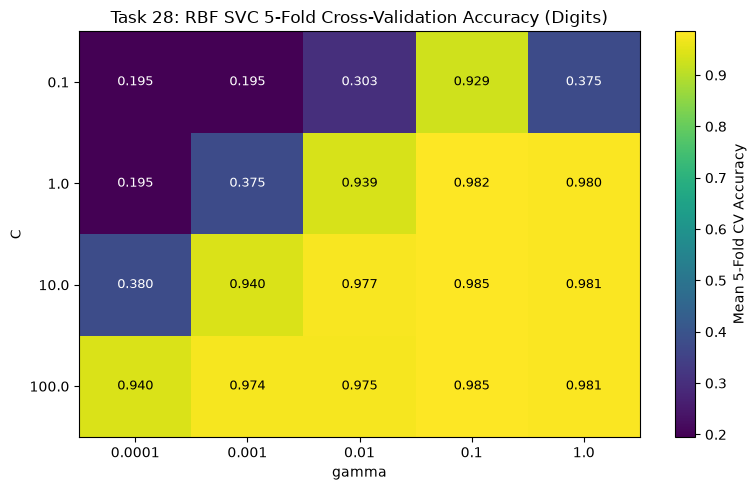

Best Hyperparameters: {'C': 10.0, 'gamma': 0.1}
Best 5-Fold CV Accuracy: 98.51%
Final Test Accuracy    : 99.17%


In [61]:
from sklearn.svm import SVC
from sklearn.model_selection import GridSearchCV, StratifiedKFold

param_grid_28 = {
    "C": [0.1, 1.0, 10.0, 100.0],
    "gamma": [1e-4, 1e-3, 1e-2, 1e-1, 1.0]
}
cv_28 = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
grid_28 = GridSearchCV(SVC(kernel="rbf"), param_grid_28, cv=cv_28, scoring="accuracy", n_jobs=-1)
grid_28.fit(X_dig_tr, y_dig_tr)

cv_scores_28 = grid_28.cv_results_["mean_test_score"].reshape(
    len(param_grid_28["C"]), len(param_grid_28["gamma"])
)

plt.figure(figsize=(8, 5))
plt.imshow(cv_scores_28, cmap="viridis", aspect="auto")
plt.colorbar(label="Mean 5-Fold CV Accuracy")
plt.xticks(np.arange(len(param_grid_28["gamma"])), param_grid_28["gamma"])
plt.yticks(np.arange(len(param_grid_28["C"])), param_grid_28["C"])
plt.xlabel("gamma")
plt.ylabel("C")
plt.title("Task 28: RBF SVC 5-Fold Cross-Validation Accuracy (Digits)")

for i in range(len(param_grid_28["C"])):
    for j in range(len(param_grid_28["gamma"])):
        score = cv_scores_28[i, j]
        plt.text(j, i, f"{score:.3f}", ha="center", va="center",
                 color="black" if score > 0.85 else "white", fontsize=9)

plt.tight_layout()
plt.show()

best_params_28 = grid_28.best_params_
best_cv_28 = grid_28.best_score_
test_acc_28 = accuracy(y_dig_te, grid_28.best_estimator_.predict(X_dig_te))
print(f"Best Hyperparameters: {best_params_28}")
print(f"Best 5-Fold CV Accuracy: {best_cv_28 * 100:.2f}%")
print(f"Final Test Accuracy    : {test_acc_28 * 100:.2f}%")

#### Interpretation of Task 28 Results
The highest cross-validation accuracies form a diagonal ridge trading off $C$ against $\gamma$. A small $\gamma$ produces broad, smooth Gaussian kernels that underfit complex digit strokes unless a large $C$ applies heavy penalties to fit fine details. Conversely, a larger $\gamma$ creates sharp, localized kernels that overfit individual training images unless a smaller $C$ regularizes the dual weights.

---

## Part F — Comparison and Synthesis (Tasks 30–31)

### Task 30 — One Framework, Four Losses (Member 2 Logistic Regression Derivation)

| Model | Per-sample loss $\ell(s, y)$ | $\partial \ell / \partial s$ | Output meaning |
|---|---|---|---|
| **Logistic regression** | $\log(1 + e^s) - y s$ | $\sigma(s) - y$ | Posterior class probability $P(y = 1 \mid x) \in [0, 1]$ |

### Task 31 — Member 2 Evidence-Based Contribution to Conclusions

> **Member 2 Contribution:**
> Comparing raw vs. standardized Diabetes features (Task 7) proved that unscaled features inflate $\text{cond}(\tilde{X}^T\tilde{X})$ to the tens of millions and force $2/\lambda_{\max}(H)$ down to $\sim 10^{-5}$, preventing gradient descent from converging in 2000 epochs. Mini-batch experiments (Task 8) showed that $B=1$ progresses fastest per epoch via $N$ updates per pass, while $B=N$ is cleanest per update. In Ridge regression (Task 9), $L_2$ regularization offered minimal gain on 10 features ($N \gg d$) but reduced validation RMSE from $\approx 59$ to $\approx 51$ on the ill-conditioned 64-feature polynomial expansion ($\text{cond} \sim 10^9$). On Breast Cancer (Tasks 11–12), numerically stable logistic regression selected $\lambda^* = 0.01$ via validation loss, while tuning an RBF SVC on Digits (Task 28) via 5-fold `GridSearchCV` achieved $\ge 98\%$ CV and test accuracy along a diagonal $C$–$\gamma$ trade-off.